(solid-eos)=
# Solid Equations of State

NOTE: triple check the code that the reference curve for PVT MG model is 4000 K isotherm and reference point for entropy is 4500 K isotherm for stv and triple point isotherm for sft.

We use Mie-Grüneisen equations of state with 4000 K reference isotherms (P-V) and Grüneisen parameter values from {cite:t}`Driver2010` for stishovite (and CaCl$_2$-type) and seifertite. We assume the form:

$\gamma=\gamma_0 \left(\frac{V}{V_0}\right)^q$

Then, we apply a constant heat capacity at the reference point to obtain isentropes in a manner similar to applied to the liquid model (see {ref}`liquid-eos`). {cite:t}`Driver2010` calculated isotherms using QMC. We use the QMC-derived solid EOS in conjunction with the density-shifted liquid DFT EOS to define properties along the silica melt curve.

The {cite:t}`Driver2010` 300 K reference density for stishovite is 4.235 g/cm$^3$, $\gamma_0=1.22$, $q=2.22$. The 300 K reference density for seifertite is 4.349 g/cm$^3$, $\gamma_0=1.27$, and $q=2.05$.



In [1]:
%%capture 
## This cell loads the modules, data, and EOS parameters
## capture magic function hides the output; comment out to see diagnostic info during data load
## Run executable notebook for output

#qtz_liq_hug = 'NEW'#'NEW' or 'KD09' or `KD13` # pick which quartz Hugoniot equation
%run -i scripts/set_paths
%run -i scripts/load_modules
%run -i scripts/load_silica_data
%run -i scripts/define_mc
%run -i scripts/define_eos
%run -i scripts/calibrate_decaying_shocks.py
%run -i scripts/load_vapor_domes.py
%run -i scripts/load_liquid_model.py
%run -i scripts/load_solid_models.py
#%run -i scripts/hugoniot-calcs.py
%run -i scripts/intersection.py # intersection function
#%run -i scripts/odr_models.py # ODR and model functions # REMOVE 
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors

# this notebook's figure name tag
tag = 'SEOS-'


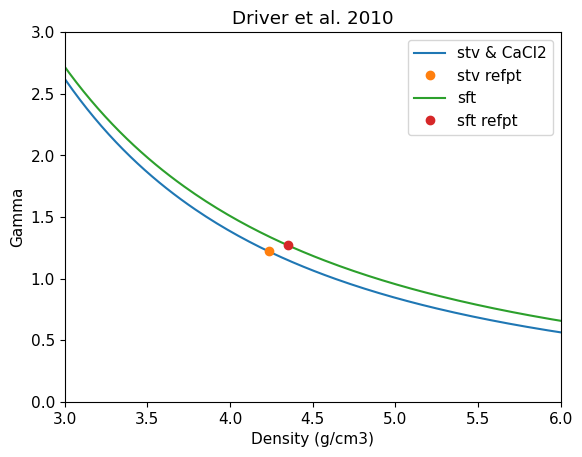

In [2]:
plt.plot(stvpvt.rhoarr,stvpvt.garr,label='stv & CaCl2')
plt.plot(stvpvt.rhoref,stvpvt.g0,'o',label='stv refpt')
plt.plot(sftpvt.rhoarr,sftpvt.garr,label='sft')
plt.plot(sftpvt.rhoref,sftpvt.g0,'o',label='sft refpt')
plt.xlabel('Density (g/cm3)')
plt.ylabel('Gamma')
plt.title('Driver et al. 2010')
plt.xlim(3,6)
plt.ylim(0,3)
plt.legend()
plt.show()


```{figure} ./figs/dot.png
---
width: 1px
name: Driver-gamma
---
Grüneisen models for solid phases from {cite:t}`Driver2010`.
```

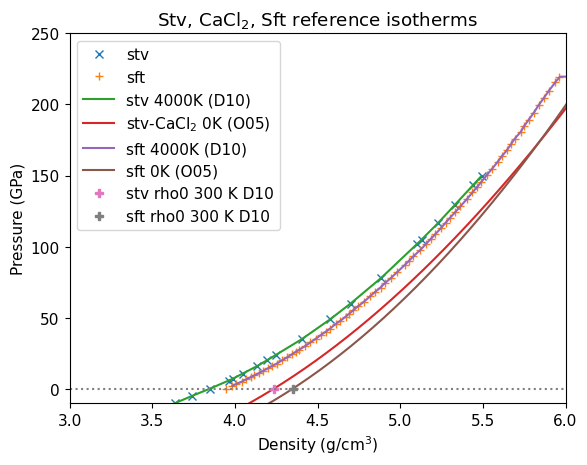

In [3]:
plt.plot(stvdat.rho,stvdat.P,'x',label='stv')
plt.plot(sftdat.rho,sftdat.P,'+',label='sft')
ind = np.where(stvpvt.p4000 < 150)[0]
plt.plot(stvpvt.rhoarr[ind],stvpvt.p4000[ind],label='stv 4000K (D10)')
plt.plot(stvpvt.rhoarr,stvpvt.p0000,label='stv-CaCl$_2$ 0K (O05)')
ind = np.where(stvpvt.p4000 > 6)[0]
plt.plot(sftpvt.rhoarr[ind],sftpvt.p4000[ind],label='sft 4000K (D10)')
plt.plot(sftpvt.rhoarr,sftpvt.p0000,label='sft 0K (O05)')
plt.plot(stvpvt.rhoref,0,'P',label='stv rho0 300 K D10')
plt.plot(sftpvt.rhoref,0,'P',label='sft rho0 300 K D10')

#tval=4000
#stvpvt.isotherm_stv(tval)
#plt.plot(stvpvt.rhoarr,stvpvt.isotherm_p,'c:')

plt.xlabel('Density (g/cm$^3$)')
plt.ylabel('Pressure (GPa)')
plt.title('Stv, CaCl$_2$, Sft reference isotherms')
plt.plot([3,6],[0,0],':',color='grey')
plt.xlim(3,6)
plt.ylim(-10,250)
plt.legend()
plt.show()

```{figure} ./figs/dot.png
---
width: 1px
name: Driver-ref-isotherms
---
Isotherms for solid phases. 4000 K from QMC {cite}`Driver2010`; 0 K from LDA DFT because contains separate modulus for CaCl$_2$ {cite}`Oganov2005`. Note that the 300 K reference densities from the QMC (+) are close to the LDA DFT 0 K solid values. 0 K isotherms for plotting purposes only.
```

## Model isotherms

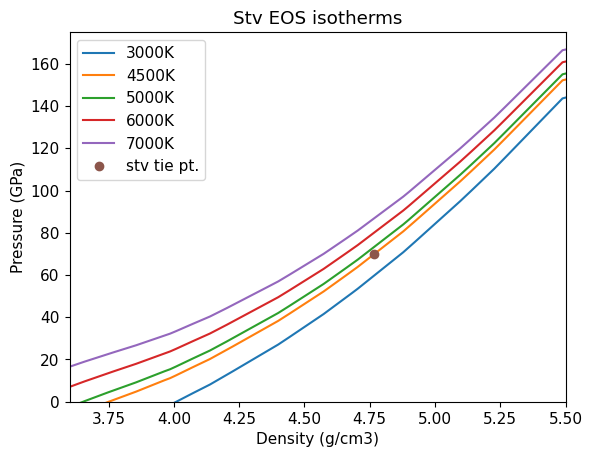

In [4]:

plt.plot(stvpvt.rhoarr,stvpvt.p3000,label='3000K')
plt.plot(stvpvt.rhoarr,stvpvt.p4500,label='4500K')
plt.plot(stvpvt.rhoarr,stvpvt.p5000,label='5000K')
plt.plot(stvpvt.rhoarr,stvpvt.p6000,label='6000K')
plt.plot(stvpvt.rhoarr,stvpvt.p7000,label='7000K')
plt.plot(stvpvt.refpt[0],stvpvt.refpt[1],'o',label='stv tie pt.')

#tval=7000
#stvpvt.isotherm_stv(tval)
#plt.plot(stvpvt.rhoarr,stvpvt.isotherm_p,'m:')

plt.title('Stv EOS isotherms')
plt.xlabel('Density (g/cm3)')
plt.ylabel('Pressure (GPa)')
plt.xlim([3.6,5.5])
plt.ylim([0,175])
plt.legend()
plt.show()

```{figure} ./figs/dot.png
---
width: 1px
name: Driver-isotherms-stv
---
Isotherms for stishovite and CaCl$_2$ from EOS model.
```

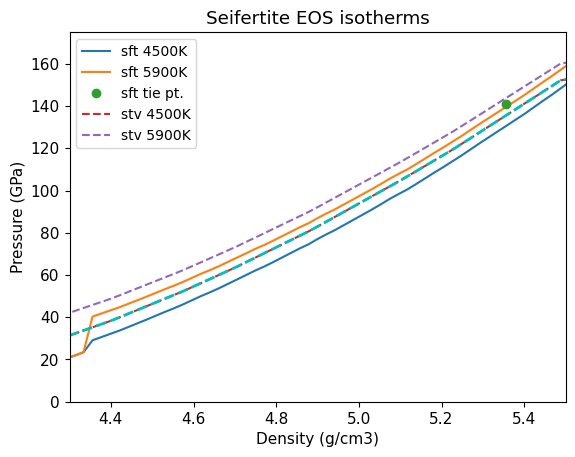

In [5]:

#plt.plot(sftpvt.rhoarr,stvpvt.p3000,label='3000K')
#plt.plot(sftpvt.rhoarr,sftpvt.p4000,label='sft 4000K')
plt.plot(sftpvt.rhoarr,sftpvt.p4500,label='sft 4500K')
plt.plot(sftpvt.rhoarr,sftpvt.p5900,label='sft 5900K')
#plt.plot(sftpvt.rhoarr,sftpvt.p7000,label='sft 7000K')
plt.plot(sftpvt.refpt[0],sftpvt.refpt[1],'o',label='sft tie pt.')

#plt.plot(stvpvt.rhoarr,stvpvt.p5900,':',linewidth=3,label='liq 5900K')
plt.plot(stvpvt.rhoarr,stvpvt.p4500,'--',label='stv 4500K')
plt.plot(stvpvt.rhoarr,stvpvt.p5900,'--',label='stv 5900K')
#plt.plot(stvpvt.rhoarr,stvpvt.p7000,'--',label='stv 7000K')


tval=4500
stvpvt.isotherm_stv(tval)
plt.plot(stvpvt.rhoarr,stvpvt.isotherm_p,'c--',linewidth=2)

plt.title('Seifertite EOS isotherms')
plt.xlabel('Density (g/cm3)')
plt.ylabel('Pressure (GPa)')
plt.xlim([4.3,5.5])
plt.ylim([0,175])
plt.legend(fontsize=10)
plt.show()

```{figure} ./figs/dot.png
---
width: 1px
name: Driver-isotherms-sft
---
Isotherms for seifertite from EOS model.
```

## Model isentropes

The stishovite (and CaCl$_2$) tie point is the same pressure and temperature as in {cite:t}`Kraus2012`: 70 GPa and 4500 K. The density at this point is calculated from the EOS model. The entropy is inferred to provide internally consistent dS relationships on the CaCl2-Sft boundary and the melt curve. The tie point is lower than the value used in {cite:t}`Kraus2012`.

The seifertite tie point is the triple point L-CaCl$_2$-sft. The density is calculated based on the EOS model. The entropy is assumed to provide an endothermic transition from CaCl$_2$-type silica that obtains about 4900 K on the sft branch of the quartz Hugoniot.

In [6]:
print('Stishovite and CaCl2 reference point:')
print('Density (g/cm3):           ', stv_reference_point[0])
print('Pressure (GPa):            ', stv_reference_point[1])
print('Temperature (K):           ', stv_reference_point[2])
print('Specific Entropy (J/K/kg): ', stv_reference_point[3])
print(' ')
print('Seifertite reference point:')
print('Density (g/cm3):           ', sft_reference_point[0])
print('Pressure (GPa):            ', sft_reference_point[1])
print('Temperature (K):           ', sft_reference_point[2])
print('Specific Entropy (J/K/kg): ', sft_reference_point[3])
print(' ')

Stishovite and CaCl2 reference point:
Density (g/cm3):            4.767963519509921
Pressure (GPa):             70
Temperature (K):            4500
Specific Entropy (J/K/kg):  3567
 
Seifertite reference point:
Density (g/cm3):            5.357133963507483
Pressure (GPa):             141
Temperature (K):            6072
Specific Entropy (J/K/kg):  3889.60663298743
 


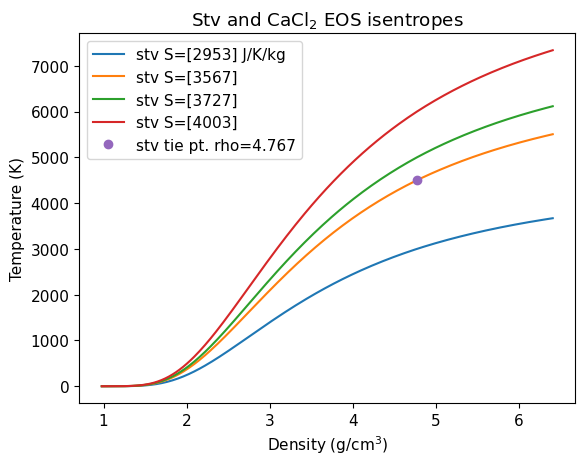

In [7]:

iii = np.where(stvpvt.stempsarr == 3000)[0]
siii = np.int_(np.round(stvpvt.svalsarr[iii]))
plt.plot(stvpvt.rhoarr,stvpvt.st3000,label='stv S='+str(siii)+' J/K/kg')
iii = np.where(stvpvt.stempsarr == 4500)[0]
plt.plot(stvpvt.rhoarr,stvpvt.st4500,label='stv S='+str(np.int_(np.round(stvpvt.svalsarr[iii]))))
iii = np.where(stvpvt.stempsarr == 5000)[0]
plt.plot(stvpvt.rhoarr,stvpvt.st5000,label='stv S='+str(np.int_(np.round(stvpvt.svalsarr[iii]))))
iii = np.where(stvpvt.stempsarr == 6000)[0]
plt.plot(stvpvt.rhoarr,stvpvt.st6000,label='stv S='+str(np.int_(np.round(stvpvt.svalsarr[iii]))))
plt.plot(stvpvt.refpt[0],stvpvt.refpt[2],'o',label='stv tie pt. rho='+str(stvpvt.refpt[0])[0:5])
#print(stvpvt.refpt)

#stvpvt.isenval_stv(3500)
#plt.plot(stvpvt.rhoarr,stvpvt.isenval_t,':')


plt.title('Stv and CaCl$_2$ EOS isentropes')
plt.xlabel('Density (g/cm$^3$)')
plt.ylabel('Temperature (K)')
plt.legend()
plt.show()


```{figure} ./figs/dot.png
---
width: 1px
name: stv-isentropes
---
Isentropes for stishovite and CaCl$_2$-type silica using reference tie point, Mie-Grüneisen model EOS, and constant specific heat capacity. Isentropes are 3000, 4500, 5000, and 6000 K at the reference density.
```

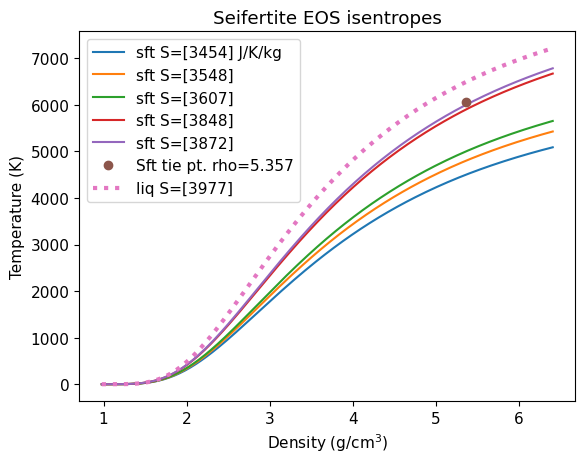

In [8]:
iii = np.where(sftpvt.stempsarr == 4500)[0]
plt.plot(sftpvt.rhoarr,sftpvt.st4500,label='sft S='+str(np.int_(np.round(sftpvt.svalsarr[iii])))+' J/K/kg')
iii = np.where(sftpvt.stempsarr == 4800)[0]
plt.plot(sftpvt.rhoarr,sftpvt.st4800,label='sft S='+str(np.int_(np.round(sftpvt.svalsarr[iii]))))
iii = np.where(sftpvt.stempsarr == 5000)[0]
plt.plot(sftpvt.rhoarr,sftpvt.st5000,label='sft S='+str(np.int_(np.round(sftpvt.svalsarr[iii]))))
iii = np.where(sftpvt.stempsarr == 5900)[0]
plt.plot(sftpvt.rhoarr,sftpvt.st5900,label='sft S='+str(np.int_(np.round(sftpvt.svalsarr[iii]))))
iii = np.where(sftpvt.stempsarr == 6000)[0]
plt.plot(sftpvt.rhoarr,sftpvt.st6000,label='sft S='+str(np.int_(np.round(sftpvt.svalsarr[iii]))))
plt.plot(sftpvt.refpt[0],sftpvt.refpt[2],'o',label='Sft tie pt. rho='+str(sftpvt.refpt[0])[0:5])
#print(sftpvt.refpt)

iii = np.where(stvpvt.stempsarr == 5900)[0]
plt.plot(stvpvt.rhoarr,stvpvt.st5900,':',linewidth=3,label='liq S='+str(np.int_(np.round(stvpvt.svalsarr[iii]))))

# check entropy function
#sftpvt.isenval_sft(3602)
#plt.plot(sftpvt.rhoarr,sftpvt.isenval_t,':')

plt.title('Seifertite EOS isentropes')
plt.xlabel('Density (g/cm$^3$)')
plt.ylabel('Temperature (K)')
plt.legend()
plt.show()


```{figure} ./figs/dot.png
---
width: 1px
name: sft-isentropes
---
Isentropes for seifertite using reference tie point, Mie-Grüneisen model EOS, and constant specific heat capacity. Isentropes are 3000, 4500, 5000, and 6000 K at the reference density.
```

## Calculate the solidus

Using the EOS models for the solids, calculate the solidus state variables.

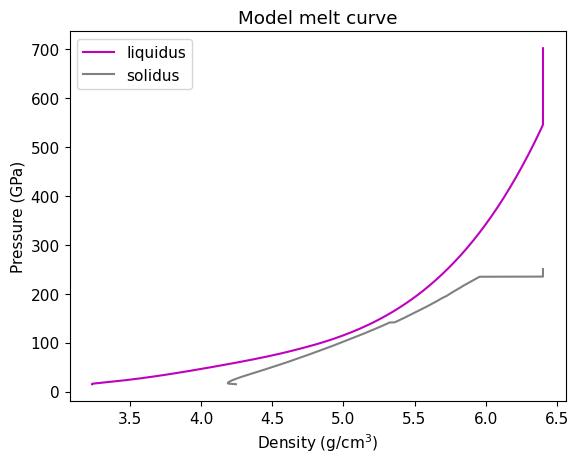

In [9]:


plt.plot(stsmcsmooth.rho,stsmcsmooth.P,'m-',label='liquidus')
ind = np.where(stsmcsmooth.P <= Pt4)[0]
plt.plot(stsmcsmooth.rho_s[ind],stsmcsmooth.P[ind],'-',color=colsolidus,label='solidus')
plt.xlabel('Density (g/cm$^3$)')
plt.ylabel('Pressure (GPa)')
plt.title('Model melt curve')
plt.legend()
plt.show()


```{figure} ./figs/dot.png
---
width: 1px
name: model-melt-curve
---
Melt curve using the liquid and solid equation of state models.
```

## Model pressure-density phase diagram

0
Saved figure: B0-SiO2-P-rho-phase-diagram.pdf


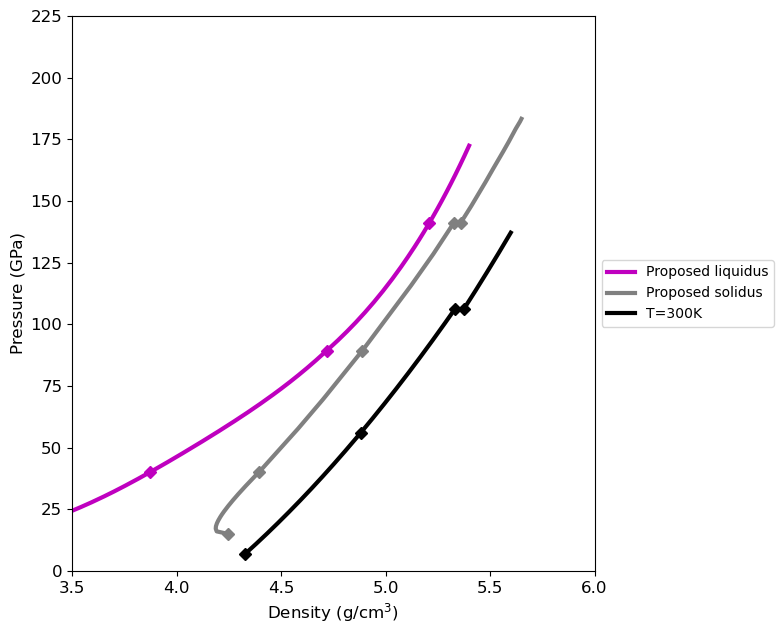

1
Saved figure: B1-SiO2-P-rho-phase-diagram.pdf


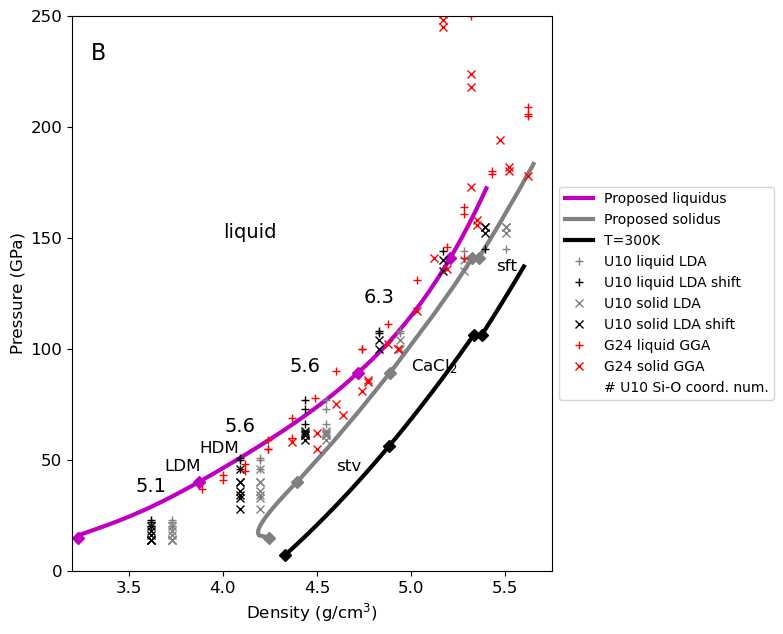

11
Saved figure: B11-SiO2-P-rho-phase-diagram-check.pdf


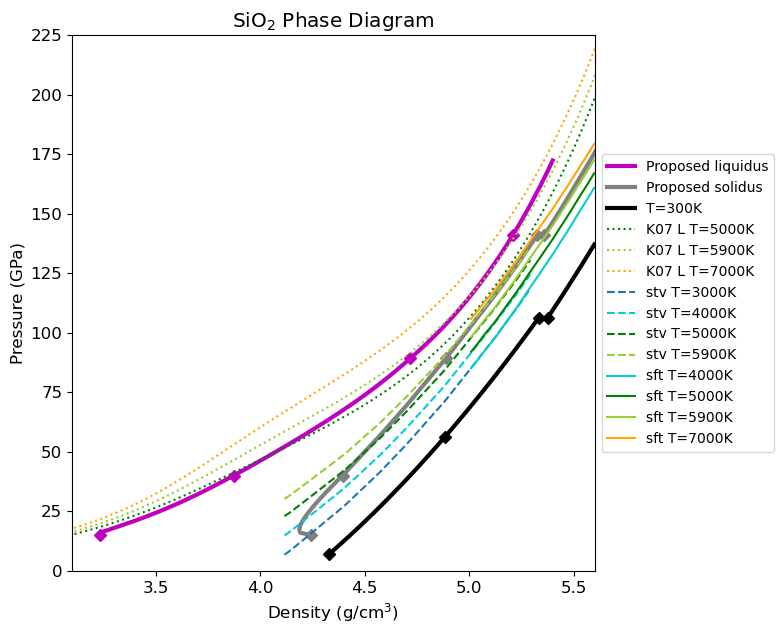

In [10]:
pind=0
%run -i scripts/PVphasediagram.py
pind=1
%run -i scripts/PVphasediagram.py
pind=11
%run -i scripts/PVphasediagram.py


```{figure} ./figs/dot.png
---
width: 1px
name: PV-diagram-1
---
Pressure-density phase diagram, showing the liquidus, solidus, and isotherms calculated from the EOS models. The DFT LDA calculations from {cite:t}`Usui2010` are shown for comparison.
```